**simple linear regression model**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")

**DATA COLLECTION**

In [14]:
df=pd.read_csv('/content/solar_power_output.csv')
df

,temperature,humidity,solar_irradiance,wind_speed,solar_power_output
0,19.363503,75.852937,266.619636,5.190818,128.101772
1,33.767858,62.887709,587.710853,4.791819,290.911789
2,28.299849,44.762209,885.651252,0.256421,442.336390
3,24.966462,85.103602,759.002398,3.412478,380.261988
4,13.900466,74.778494,825.905033,3.801956,415.931953
...,...,...,...,...,...
495,18.833806,27.326566,701.391519,6.569552,352.480220
496,24.591403,93.385086,657.541311,9.566146,326.834297
497,11.943366,30.945490,517.144639,0.689580,259.133251
498,34.359870,96.018988,441.807202,0.570547,223.778239


In [ ]:
df.shape

(500, 5)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   temperature         500 non-null    float64
 1   humidity            500 non-null    float64
 2   solar_irradiance    500 non-null    float64
 3   wind_speed          500 non-null    float64
 4   solar_power_output  500 non-null    float64
dtypes: float64(5)
memory usage: 19.7 KB


In [ ]:
df.describe().round(2)

,temperature,humidity,solar_irradiance,wind_speed,solar_power_output
count,500.00,500.00,500.00,500.00,500.00
mean,22.46,58.56,565.80,4.96,283.30
std,7.47,22.84,267.47,2.87,133.84
min,10.13,20.37,104.45,0.03,46.83
25%,16.03,38.33,317.11,2.41,158.41
50%,22.83,57.75,585.76,5.09,290.50
75%,28.90,78.11,799.61,7.37,402.00
max,34.82,99.98,999.47,9.98,502.22


**Exploratory Data Analysis (EDA)**

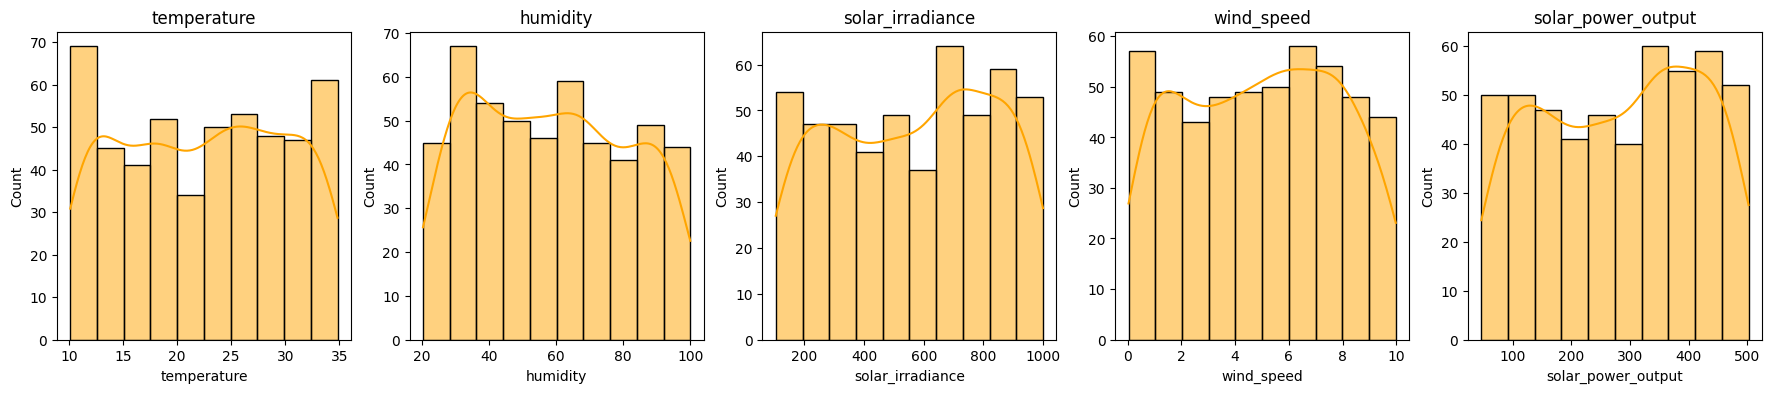

In [15]:
fig,axes = plt.subplots(1,5,figsize=(22,4))
for ax,col in zip(axes,df.columns):
  sns.histplot(df[col],kde=True,ax=ax,color="orange")
  ax.set_title(col)
plt.show()

**Bivariate Analysis** : Scatter plot with Regression line

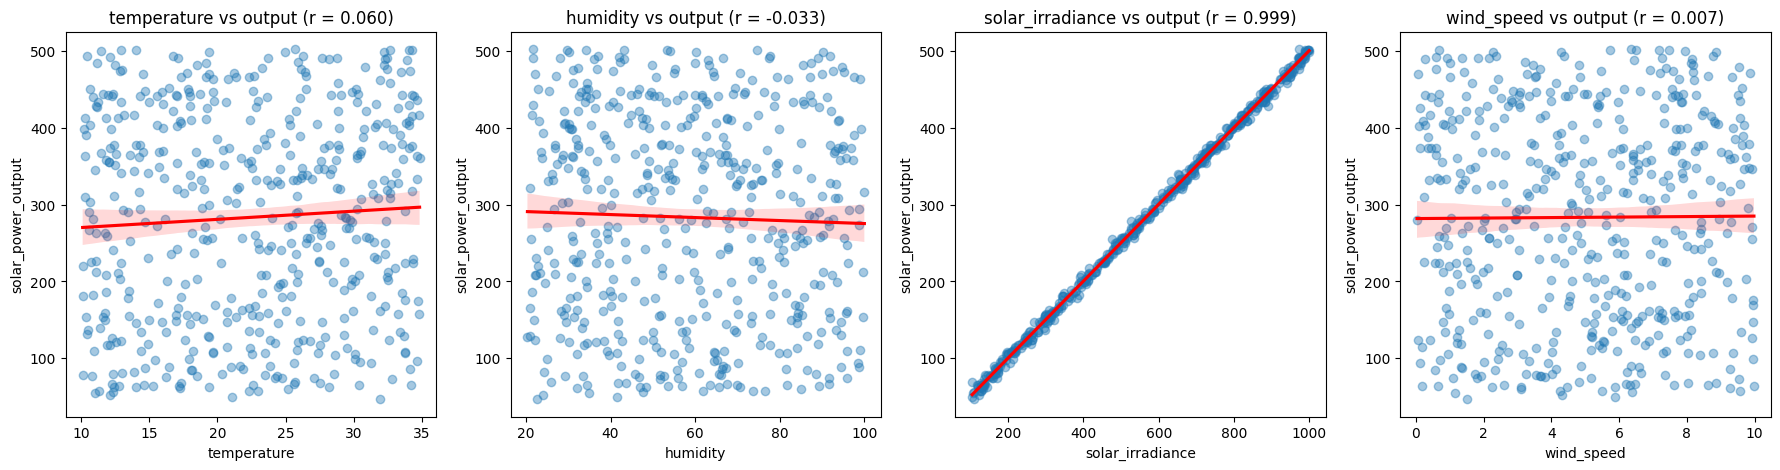

In [16]:
features = ["temperature", "humidity", "solar_irradiance", "wind_speed"]
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, col in zip(axes, features):
    sns.regplot(x=df[col], y=df["solar_power_output"], ax=ax,
                scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
    r = df[col].corr(df["solar_power_output"])
    ax.set_title(f"{col} vs output (r = {r:.3f})")
plt.show()

**Multivariate Analysis** : correlation Heatmap

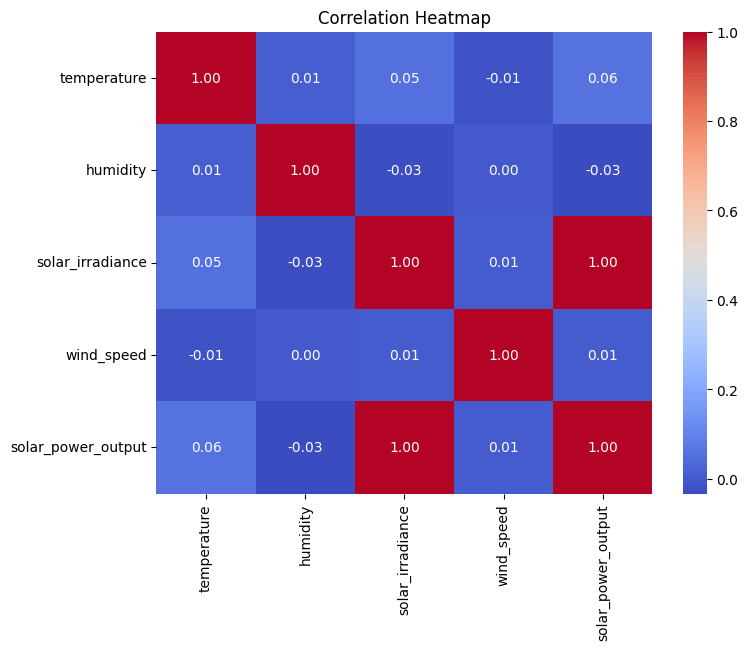

In [17]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [20]:
df.duplicated().sum()

np.int64(0)

In [25]:
x=df[["solar_irradiance"]]
y=df["solar_power_output"]

Data Splitting

In [27]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state =42)
print(X_train.shape,X_test.shape)

(400, 1) (100, 1)


**Algorithm Selection**

**Model Training**

In [30]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 0.5005361509109775
Intercept: 0.010596780972093711


Model Evaluation : Training Data

In [32]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
y_pred=model.predict(X_test)
print("R2:",r2_score(y_test,y_pred))
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))

R2: 0.9981624336592926
MAE: 4.272564495023546
MSE: 32.33319189996614


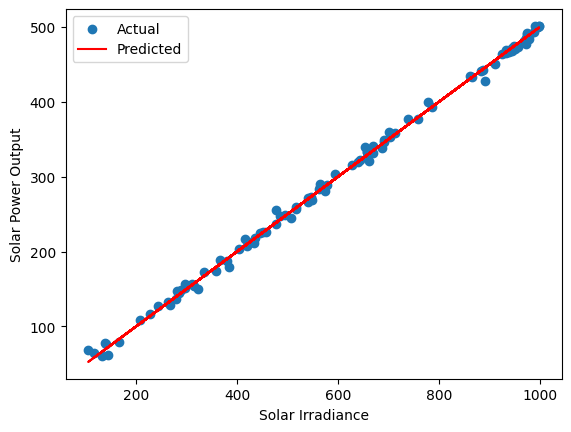

In [37]:
plt.scatter(X_test, y_test, label="Actual")
plt.plot(X_test, y_pred, color="red", label="Predicted")
plt.xlabel("Solar Irradiance")
plt.ylabel("Solar Power Output")
plt.legend()
plt.show()

In [38]:
import joblib
joblib.dump(model, 'model.pkl')
print("model saved")

model saved
